# Matplotlib: Format Charts

In [ ]:
!pip install datasets
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt 

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

<Axes: xlabel='job_title_short'>

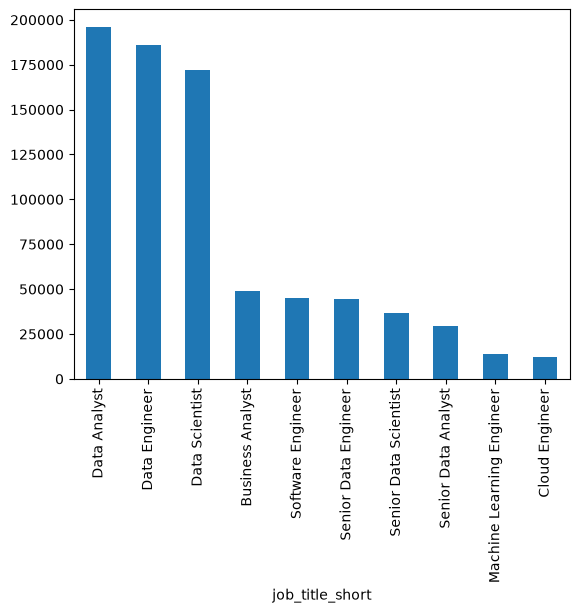

In [ ]:
fig, ax = plt.subplots()

df['job_title_short'].value_counts().plot(kind='bar', ax = ax)

In [ ]:
df['job_schedule_type'].value_counts().head(3)

job_schedule_type
Full-time     701727
Contractor     34793
Internship      8742
Name: count, dtype: int64

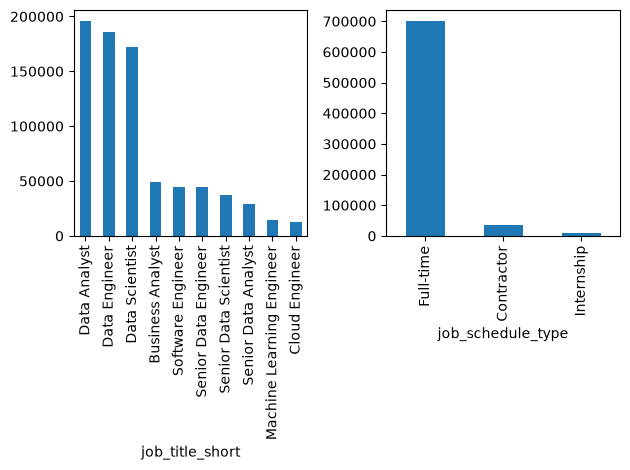

In [ ]:
fig, ax = plt.subplots(1, 2)

df['job_title_short'].value_counts().plot(kind='bar', ax=ax[0])
df['job_schedule_type'].value_counts().head(3).plot(kind='bar', ax=ax[1])

fig.tight_layout()

In [ ]:
df_skills = df.copy()
df_skills = df_skills.explode('job_skills')
skills_count = df_skills.groupby(['job_skills', 'job_title_short']).size()
df_skills_count = skills_count.reset_index(name='skill_count')
df_skills_count.sort_values(by='skill_count', ascending=False, inplace=True)
job_titles = df_skills_count['job_title_short'].unique().tolist()

df_skills_count

,job_skills,job_title_short,skill_count
1480,python,Data Scientist,113711
1822,sql,Data Engineer,113130
1479,python,Data Engineer,108022
1821,sql,Data Analyst,92428
1823,sql,Data Scientist,78982
...,...,...,...
2173,webex,Senior Data Scientist,1
293,codecommit,Business Analyst,1
2233,xamarin,Machine Learning Engineer,1
1087,mlr,Machine Learning Engineer,1


In [ ]:
job_titles = ['Data Scientist', 'Data Engineer', 'Data Analyst']

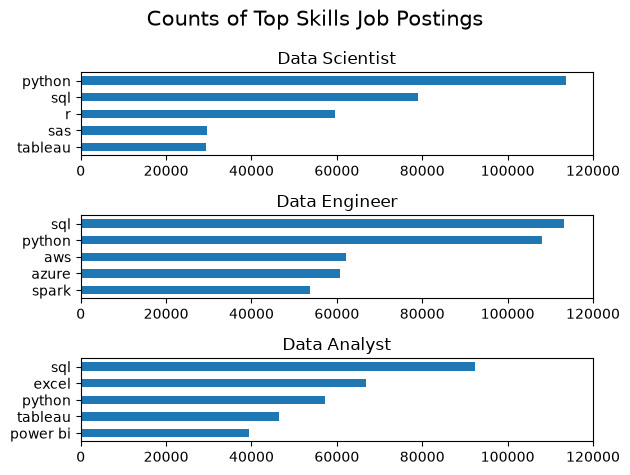

In [ ]:
fig, ax = plt.subplots(3, 1)

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_count[df_skills_count['job_title_short'] == job_title].head(5)
    df_plot.plot(kind='barh', x='job_skills', y='skill_count', ax=ax[i], title=job_title)
    ax[i].invert_yaxis()
    ax[i].set_ylabel('')
    ax[i].legend().set_visible(False)
    ax[i].set_xlim(0, 120000)

fig.suptitle('Counts of Top Skills Job Postings', fontsize=15)

fig.tight_layout()

### Subplots with Bar Charts

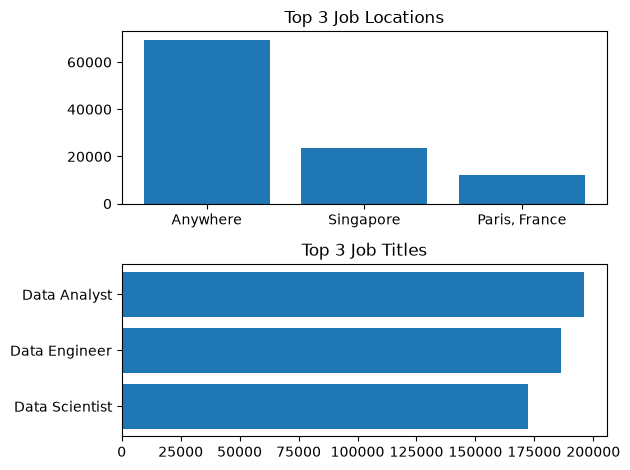

In [ ]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

fig, ax = plt.subplots(2, 1)

# Top 3 job locations
job_locations = df['job_location'].value_counts().head(3)
ax[0].bar(job_locations.index, job_locations.values)
ax[0].set_title('Top 3 Job Locations')

# Top 3 job titles
job_titles = df['job_title_short'].value_counts().head(3)
ax[1].barh(job_titles.index, job_titles.values)
ax[1].set_title('Top 3 Job Titles')
ax[1].invert_yaxis()

fig.tight_layout()
plt.show()


### Subplots with Job Titles by Schedule

In [ ]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

fig, ax = plt.subplots(2, 2)

# Job schedule types
schedules = ['Full-time', 'Part-time', 'Contractor', 'Internship']

for i, schedule in enumerate(schedules):
    df_schedule = df[df['job_schedule_type'] == schedule]
    job_titles = df_schedule['job_title_short'].value_counts().head(3)
    ax[i//2, i%2].bar(job_titles.index, job_titles.values)
    ax[i//2, i%2].set_title(f'Top 3 Job Titles ({schedule})')

fig.tight_layout()
plt.show()


In [ ]:
fig, ax=plt.subplots(2, 2)
schedules = ['Full-time', 'Part-time', 'Contractor', 'Internship']
for i, schedule in enumerate(schedules):
    df_schedule = df[df['job_schedule_type'] == schedule]
    df_job_title = df_schedule['job_title_short'].value_counts().head(3)
    ax[i//2, i%2].bar(df_job_title.index, df_job_title.values)
    ax[i//2, i%].set_title(f'Top 3 Job Titles ({schedule})')

fig.tight_layout()
plt.show()


,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
228,Data Engineer,Intern Data Preparation Automation and AI (m/f...,"Munich, Germany",via XING,Internship,False,Germany,2023-10-20 13:18:58,False,False,Germany,NaN,NaN,NaN,Munich Re,"[python, sql, r, git]","{'other': ['git'], 'programming': ['python', '..."
374,Data Analyst,Data Analyst (Intern),Taiwan,via Ai-Jobs.net,Internship,False,Taiwan,2023-06-02 13:43:03,False,False,Taiwan,NaN,NaN,NaN,Appier,"[sql, python, r, spark, tableau]","{'analyst_tools': ['tableau'], 'libraries': ['..."
452,Data Analyst,Data Analyst (Alternance),"La Possession, Réunion",via LinkedIn Reunion,Internship,False,Réunion,2023-11-16 13:46:55,False,False,Réunion,NaN,NaN,NaN,PHILIP MORRIS REUNION,[chef],{'other': ['chef']}
473,Data Analyst,Data Analyst H/F,"Lyon, France",via BeBee,Internship,False,France,2023-03-05 13:27:51,False,False,France,NaN,NaN,NaN,Eco-déchets Environnement,"[python, r]","{'programming': ['python', 'r']}"
579,Data Scientist,"Intern, Data Science",Singapore,via BeBee Singapore,Internship,False,Singapore,2023-12-24 13:17:11,False,False,Singapore,NaN,NaN,NaN,Munich Re,"[r, python, c#, azure, rshiny, power bi]","{'analyst_tools': ['power bi'], 'cloud': ['azu..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
784810,Machine Learning Engineer,Intern | Machine Learning (Generative AI),Singapore,via Ai-Jobs.net,Internship,False,Singapore,2023-01-09 06:35:06,False,False,Singapore,NaN,NaN,NaN,Bosch Group,"[python, spark, scikit-learn, plotly]","{'libraries': ['spark', 'scikit-learn', 'plotl..."
785074,Data Analyst,Stage - Data Analyst F/H,"Bois-Colombes, France",via WIZBII,Internship,False,France,2023-01-03 06:32:55,True,False,France,NaN,NaN,NaN,Stage,NaN,NaN
785281,Data Engineer,Student Worker - Data Platform Engineering,Anywhere,via JobTeaser,Internship,True,Denmark,2023-10-25 06:58:51,False,False,Denmark,NaN,NaN,NaN,The LEGO Group,"[aws, azure, databricks, flow, kubernetes, ter...","{'cloud': ['aws', 'azure', 'databricks'], 'oth..."
785438,Data Scientist,Stagiaire Data Scientist Graph Anomaly Detecti...,"Montreuil, France",via BeBee,Internship,False,France,2023-01-29 06:16:33,False,False,France,NaN,NaN,NaN,BNP Paribas Real Estate,"[python, nosql, sql, scikit-learn]","{'libraries': ['scikit-learn'], 'programming':..."


### Top Skills for Job Roles Subplots


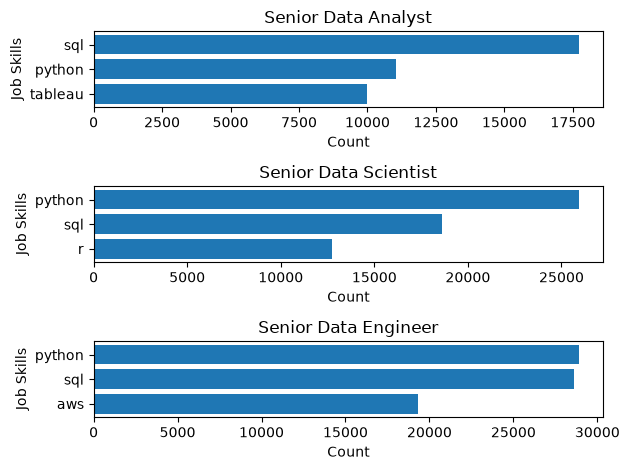

In [ ]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import ast

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

df_skills = df.explode('job_skills')
job_roles = ['Senior Data Analyst', 'Senior Data Scientist', 'Senior Data Engineer']
fig, ax = plt.subplots(len(job_roles), 1)
for i, role in enumerate(job_roles):
    role_skills = df_skills[df_skills['job_title_short'] == role]['job_skills'].value_counts().head(3)
    ax[i].barh(role_skills.index, role_skills.values)
    ax[i].set_title(role)
    ax[i].set_xlabel('Count')
    ax[i].set_ylabel('Job Skills')
    ax[i].invert_yaxis()
fig.tight_layout()
plt.show()

In [ ]:
df_skills = df.explode('job_skills')